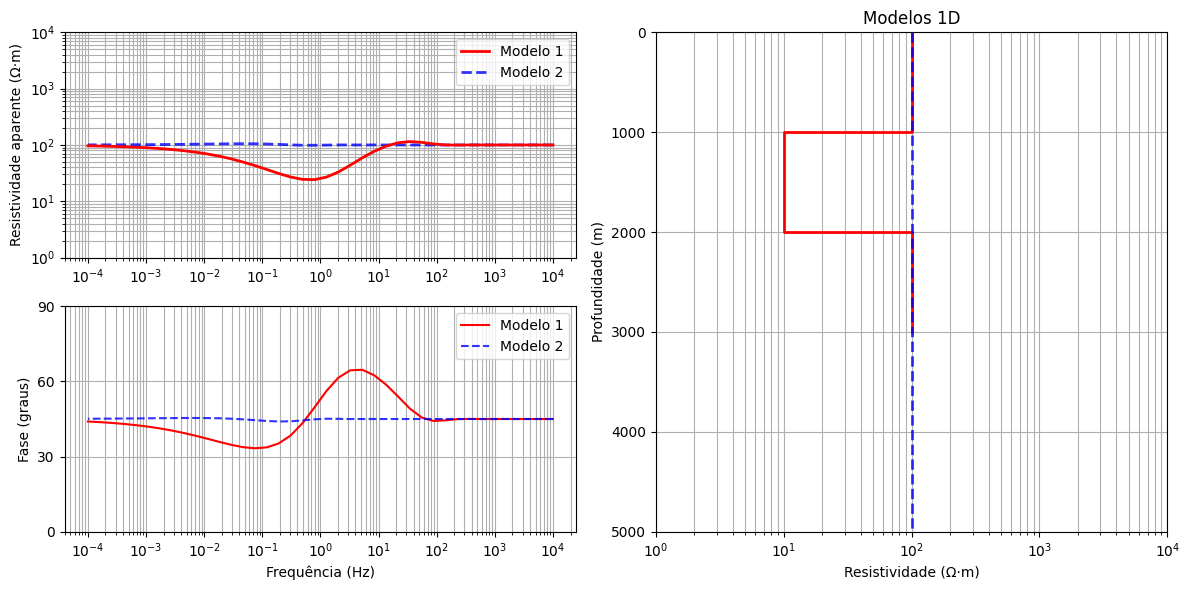

In [4]:
from matplotlib.lines import lineStyles
import numpy as np
import matplotlib.pyplot as plt

# Frequências e constantes

frequencias = np.logspace(4, -4, 40)
mu0 = 4 * np.pi * 1e-7
camadas = 3

omega = 2 * np.pi * frequencias
omega = omega[:, np.newaxis]


# Modelo 1

resistivities1 = np.array([100, 10, 100])
h1 = np.array([1000, 1000])
sigma1 = 1 / resistivities1
sigma1_calc = sigma1[np.newaxis, :]

# Modelo 2

resistivities2 = np.array([100, 10000, 100])
h2 = np.array([10000, 1000])

sigma2 = 1 / resistivities2
sigma2_calc = sigma2[np.newaxis, :]

# Modelo 3
#resistivities3 = np.array([100, 100, 1, 10, 100])
#h3 = np.array([15000, 5000, 5000, 5000])

#sigma3 = 1 / resistivities3
#sigma3_calc = sigma3[np.newaxis, :]

#Modelo 4
#resistivities4 = np.array([100, 10, 10, 1, 100])
#h4= np.array([20000, 5000, 5000, 5000])

#sigma4 = 1 / resistivities4
#sigma4_calc = sigma4[np.newaxis, :]

# Função MT

def forward_mt(sigma_calc, h):
    gamma = np.sqrt(1j * omega * mu0 * sigma_calc)
    eta = np.sqrt(1j * omega * mu0 / sigma_calc)

    z = np.zeros(len(frequencias), dtype=complex)

    for i in range(len(frequencias)):
        eta_i = eta[i, :]
        gamma_i = gamma[i, :]

        eta_total = eta_i[-1]

        for j in reversed(range(camadas - 1)):
            eta_total = eta_i[j] * (
                (eta_total + eta_i[j] * np.tanh(gamma_i[j] * h[j])) /
                (eta_i[j] + eta_total * np.tanh(gamma_i[j] * h[j]))
            )

        z[i] = eta_total

    rho_a = (np.abs(z) ** 2) / (mu0 * omega.flatten())
    fase = np.angle(z, deg=True)

    return rho_a, fase


# Cálculo dos modelos

rho1, fase1 = forward_mt(sigma1_calc, h1)
rho2, fase2 = forward_mt(sigma2_calc, h2)
#rho3, fase3 = forward_mt(sigma3_calc, h3)
#rho4, fase4 = forward_mt(sigma4_calc, h4)

# Modelos 1D

def plot_model(ax, resistivities, h, color, title= None, max_depht=50000, linestyle='-', alpha=0.5):
    rho_plot = []
    prof_plot = []

    prof = np.concatenate(([0], np.cumsum(h)))

    for i in range(len(resistivities) - 1):
        rho_plot.extend([resistivities[i], resistivities[i]])
        prof_plot.extend([prof[i], prof[i + 1]])

    rho_plot.extend([resistivities[-1], resistivities[-1]])
    prof_plot.extend([prof[-1], prof[-1] + 1000])

    ax.plot(rho_plot, prof_plot, color=color, linewidth=2, linestyle=linestyle, alpha=alpha)
    ax.set_xscale('log')
    ax.set_xlabel('Resistividade (Ω·m)')
    ax.set_ylabel('Profundidade (m)')
    if title:
        ax.set_title(title)
    ax.grid(True, which='both')


# Figura
fig = plt.figure(figsize=(12, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[4, 4])

# Dados principais
ax_rho = fig.add_subplot(gs[0, 0])
ax_phase = fig.add_subplot(gs[1, 0])

# Modelos
ax_model = fig.add_subplot(gs[:, 1])


# RESPOSTA MODELO 1
ax_rho.loglog(frequencias, rho1, color='red', label=r'Modelo 1', linewidth=2, zorder=3, alpha=1.0)
ax_phase.semilogx(frequencias, fase1, color='red', label='Modelo 1', alpha=1.0)

# RESPOSTA MODELO 2
ax_rho.loglog(frequencias, rho2, color='blue', label=r'Modelo 2', linewidth=2, zorder=2, alpha=0.8, linestyle='--')
ax_phase.semilogx(frequencias, fase2, color='blue', label='Modelo 2', alpha=0.8, linestyle='--')

#RESPOSTA MODELO 3
#ax_rho.loglog(frequencias, rho3, color='red', label=r'Modelo 3', linewidth=2, zorder=1, alpha=0.6)
#ax_phase.semilogx(frequencias, fase3, color='red', label='Modelo 3', alpha=0.6)

#RESPOSTA MODELO 4
#ax_rho.loglog(frequencias, rho4, color='red', label=r'Modelo 4', linewidth=2, zorder=0, alpha=0.4)
#ax_phase.semilogx(frequencias, fase4, color='red', label='Modelo 4', alpha=0.4)

# FORMATOS
ax_rho.set_ylabel('Resistividade aparente (Ω·m)')
ax_rho.set_ylim(10**0, 10**4)
ax_rho.grid(True, which='both')
ax_rho.legend()

ax_phase.set_xlabel('Frequência (Hz)')
ax_phase.set_yticks([0, 30, 60, 90])
ax_phase.set_ylabel('Fase (graus)')
ax_phase.grid(True, which='both')
ax_phase.legend()

# MODELOS 1D
plot_model(ax_model, resistivities1, h1, 'red', 'Modelos 1D', alpha=1.0)
plot_model(ax_model, resistivities2, h2, 'blue', 'Modelos 1D',alpha=0.8, linestyle='--')
#plot_model(ax_model, resistivities3, h3, 'red', 'Modelos 1D',alpha=0.6)
#plot_model(ax_model, resistivities4, h4, 'red', 'Modelos 1D',alpha=0.4)

#FORMATOS
#max_total_depth = h4.sum() + 1000
ax_model.set_xlim(10**0, 10**4)
#ax_model.set_ylim(0, max_total_depth + 1000)
ax_model.set_ylim(0, 5000)
ax_model.invert_yaxis()

plt.tight_layout()
plt.show()